In [ ]:
!pip -q install openpyxl statsmodels scikit-learn

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display, Markdown
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

archivo = "Proyecto_Filtros_Automotrices (1).xlsx"
if not os.path.exists(archivo):
    print("Sube el Excel del caso AutoPartes Sur.")
    cargados = files.upload()
    candidatos = [n for n in cargados if n.lower().endswith((".xlsx", ".xls"))]
    if not candidatos:
        raise FileNotFoundError("No se recibió un Excel.")
    archivo = candidatos[0]

xls = pd.ExcelFile(archivo)
print("Hojas:", xls.sheet_names)
if "Demanda_Historica" not in xls.sheet_names:
    raise ValueError("No existe la hoja Demanda_Historica.")

datos = pd.read_excel(archivo, sheet_name="Demanda_Historica")
display(datos.head())

Sube el Excel del caso AutoPartes Sur.


Saving Proyecto_Filtros_Automotrices (1).xlsx to Proyecto_Filtros_Automotrices (1).xlsx
Hojas: ['Proyecto', 'Demanda_Historica', 'Parametros']


,Mes (AAAA-MM),Demanda (filtros)
0,2020-01,2290
1,2020-02,2830
2,2020-03,3450
3,2020-04,4150
4,2020-05,4790


In [ ]:
col_fecha = "Mes (AAAA-MM)"
col_demanda = "Demanda (filtros)"
if col_fecha not in datos.columns or col_demanda not in datos.columns:
    raise ValueError(f"Columnas inesperadas: {list(datos.columns)}")

df = datos[[col_fecha, col_demanda]].copy()
df.columns = ["Mes", "Demanda"]
df["Mes"] = pd.to_datetime(df["Mes"].astype(str), format="%Y-%m", errors="coerce")
df["Demanda"] = pd.to_numeric(df["Demanda"], errors="coerce")
df = df.sort_values("Mes").reset_index(drop=True)

fechas = df["Mes"].dropna().sort_values()
rango = pd.date_range(fechas.min(), fechas.max(), freq="MS")
control = pd.DataFrame({
    "Control": ["Observaciones", "Fechas faltantes", "Demandas faltantes",
                "Fechas duplicadas", "Demandas no positivas", "Meses ausentes"],
    "Resultado": [len(df), int(df["Mes"].isna().sum()), int(df["Demanda"].isna().sum()),
                  int(df["Mes"].duplicated().sum()), int((df["Demanda"].dropna() <= 0).sum()),
                  len(set(rango) - set(fechas))]
})
display(control)
if control["Resultado"].iloc[1:].sum() > 0:
    raise ValueError("La base presenta problemas; revisar antes de modelar.")

y = df.set_index("Mes").asfreq("MS")["Demanda"].astype(float)
print(f"Periodo: {y.index.min():%Y-%m} a {y.index.max():%Y-%m} | Observaciones: {len(y)}")

,Control,Resultado
0,Observaciones,60
1,Fechas faltantes,0
2,Demandas faltantes,0
3,Fechas duplicadas,0
4,Demandas no positivas,0
5,Meses ausentes,0


Periodo: 2020-01 a 2024-12 | Observaciones: 60


,Indicador,Valor
0,Promedio,"7,497.17"
1,Mediana,"7,520.00"
2,Desviación estándar,"2,021.62"
3,Mínimo,"2,290.00"
4,Máximo,"12,070.00"
5,Coeficiente de variación (%),26.97


,Demanda anual,Promedio mensual
Año,,
2020,"57,040.00","4,753.33"
2021,"82,260.00","6,855.00"
2022,"93,630.00","7,802.50"
2023,"106,070.00","8,839.17"
2024,"110,830.00","9,235.83"


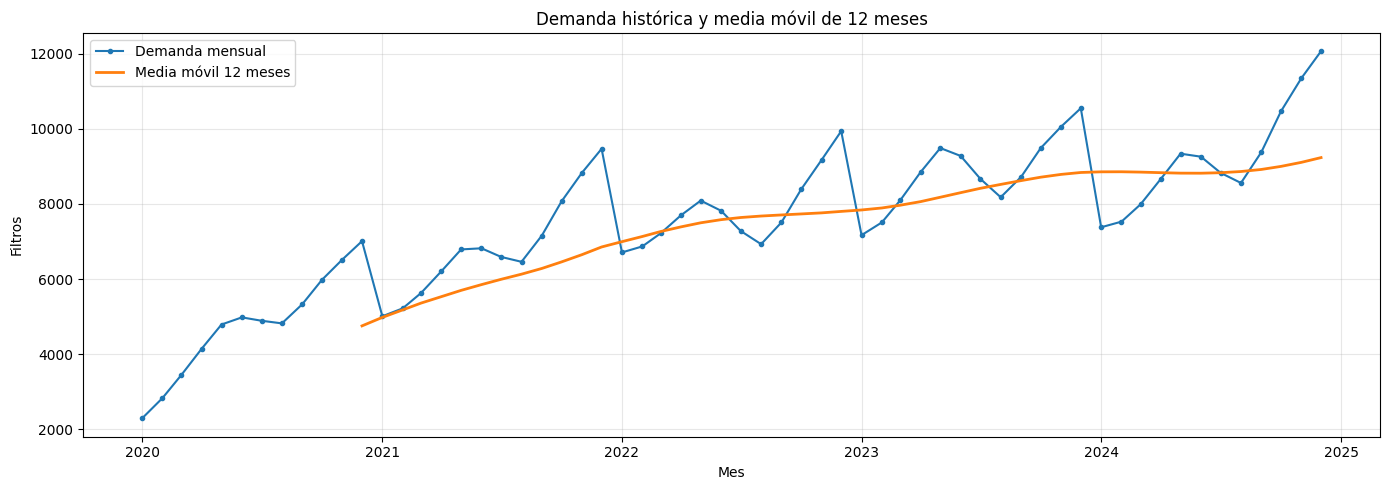

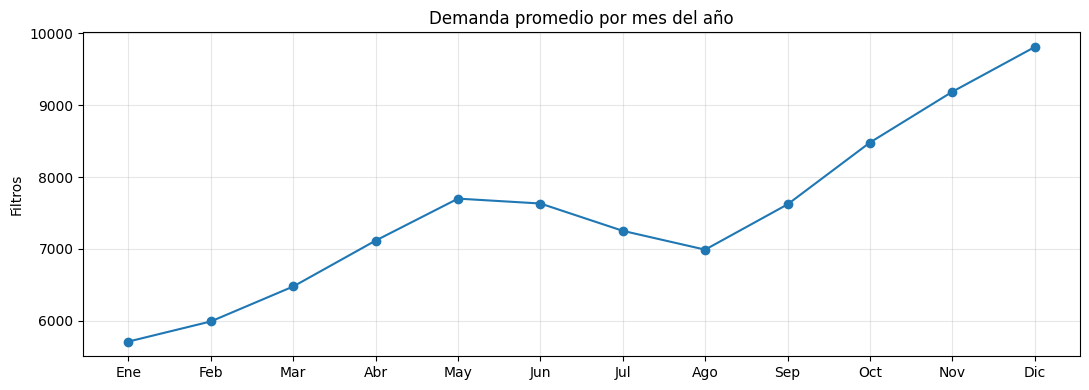

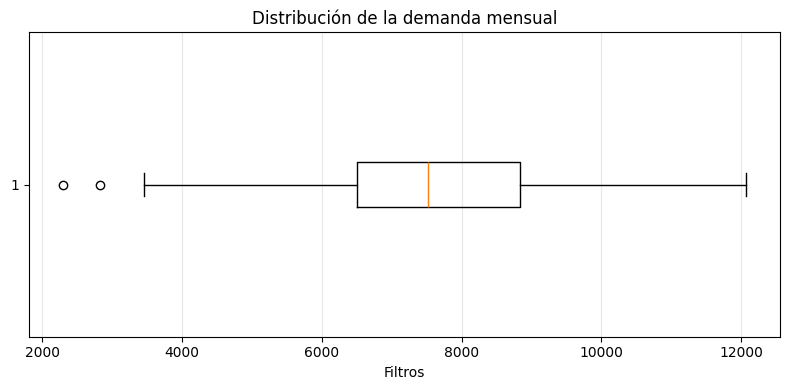

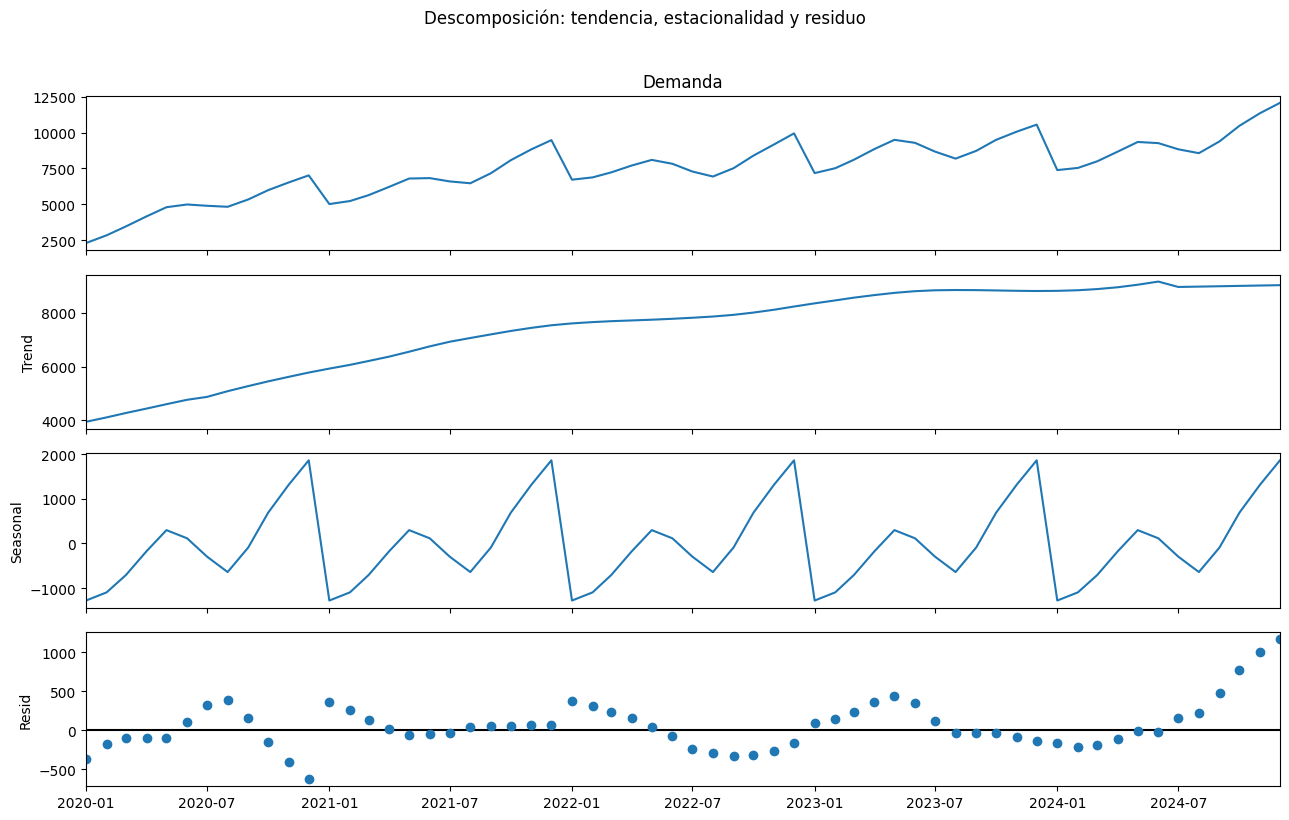

In [ ]:
estadisticos = pd.DataFrame({
    "Indicador": ["Promedio", "Mediana", "Desviación estándar", "Mínimo", "Máximo", "Coeficiente de variación (%)"],
    "Valor": [y.mean(), y.median(), y.std(), y.min(), y.max(), y.std()/y.mean()*100]
})
display(estadisticos)

anual = y.resample("YE").agg(["sum", "mean"])
anual.index = anual.index.year
anual.columns = ["Demanda anual", "Promedio mensual"]
anual.index.name = "Año"
display(anual)

plt.figure(figsize=(14,5))
plt.plot(y.index, y, marker="o", markersize=3, label="Demanda mensual")
plt.plot(y.index, y.rolling(12).mean(), linewidth=2, label="Media móvil 12 meses")
plt.title("Demanda histórica y media móvil de 12 meses")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

meses = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
perfil = y.groupby(y.index.month).mean()
plt.figure(figsize=(11,4))
plt.plot(meses, perfil.values, marker="o")
plt.title("Demanda promedio por mes del año"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,4))
plt.boxplot(y.values, vert=False)
plt.title("Distribución de la demanda mensual"); plt.xlabel("Filtros"); plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

descomp = seasonal_decompose(y, model="additive", period=12, extrapolate_trend="freq")
fig = descomp.plot(); fig.set_size_inches(13,8)
fig.suptitle("Descomposición: tendencia, estacionalidad y residuo", y=1.02)
plt.tight_layout(); plt.show()

In [ ]:
corte = pd.Timestamp("2024-01-01")
train = y.loc[y.index < corte]
test = y.loc[y.index >= corte]
if len(train) != 48 or len(test) != 12:
    raise ValueError(f"Se esperaban 48/12 observaciones; se obtuvieron {len(train)}/{len(test)}.")
print(f"Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)} meses)")
print(f"Validación: {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({len(test)} meses)")

Entrenamiento: 2020-01 a 2023-12 (48 meses)
Validación: 2024-01 a 2024-12 (12 meses)


In [ ]:
def metricas(real, pred):
    real, pred = np.asarray(real, float), np.asarray(pred, float)
    return {
        "MAE": mean_absolute_error(real, pred),
        "MSE": mean_squared_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "MAPE (%)": np.mean(np.abs((real-pred)/real))*100,
        "Sesgo (real - pronóstico)": np.mean(real-pred)
    }

preds = {}
preds["Naive estacional"] = train.iloc[-12:].values

hw_add = ExponentialSmoothing(train, trend="add", seasonal="add",
    seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
preds["Holt-Winters aditivo"] = hw_add.forecast(12).values

hw_damp = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add",
    seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
preds["Holt-Winters amortiguado"] = hw_damp.forecast(12).values

hw_mult = ExponentialSmoothing(train, trend="mul", seasonal="add",
    seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
preds["Holt-Winters tendencia multiplicativa"] = hw_mult.forecast(12).values

LAGS = [1, 2, 3, 6, 12]
def features(hist, fecha):
    fila = {f"lag_{lag}": hist.iloc[-lag] for lag in LAGS}
    fila["mes_sin"] = np.sin(2*np.pi*fecha.month/12)
    fila["mes_cos"] = np.cos(2*np.pi*fecha.month/12)
    fila["t"] = len(hist)
    return pd.DataFrame([fila])

def dataset_rf(serie):
    X, yy = [], []
    for i in range(max(LAGS), len(serie)):
        X.append(features(serie.iloc[:i], serie.index[i]).iloc[0].to_dict())
        yy.append(serie.iloc[i])
    return pd.DataFrame(X), np.asarray(yy)

Xrf, yrf = dataset_rf(train)
rf = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
rf.fit(Xrf, yrf)

# Predicción recursiva: cada pronóstico pasa a formar parte del historial.
hist = train.copy()
prf = []
for fecha in test.index:
    valor = float(rf.predict(features(hist, fecha))[0])
    prf.append(valor)
    hist.loc[fecha] = valor
preds["Random Forest"] = np.asarray(prf)

tabla_metricas = pd.DataFrame([
    {"Modelo": nombre, **metricas(test.values, pred)}
    for nombre, pred in preds.items()
]).sort_values("RMSE").reset_index(drop=True)
display(tabla_metricas.round(2))

,Modelo,MAE,MSE,RMSE,MAPE (%),Sesgo (real - pronóstico)
0,Holt-Winters aditivo,585.87,"421,870.92",649.52,6.85,-572.05
1,Naive estacional,473.33,"471,033.33",686.32,4.58,396.67
2,Holt-Winters amortiguado,604.07,"594,566.08",771.08,6.22,252.93
3,Holt-Winters tendencia multiplicativa,741.24,"632,448.75",795.27,8.49,-741.24
4,Random Forest,968.57,"1,163,823.53","1,078.81",10.76,-370.81


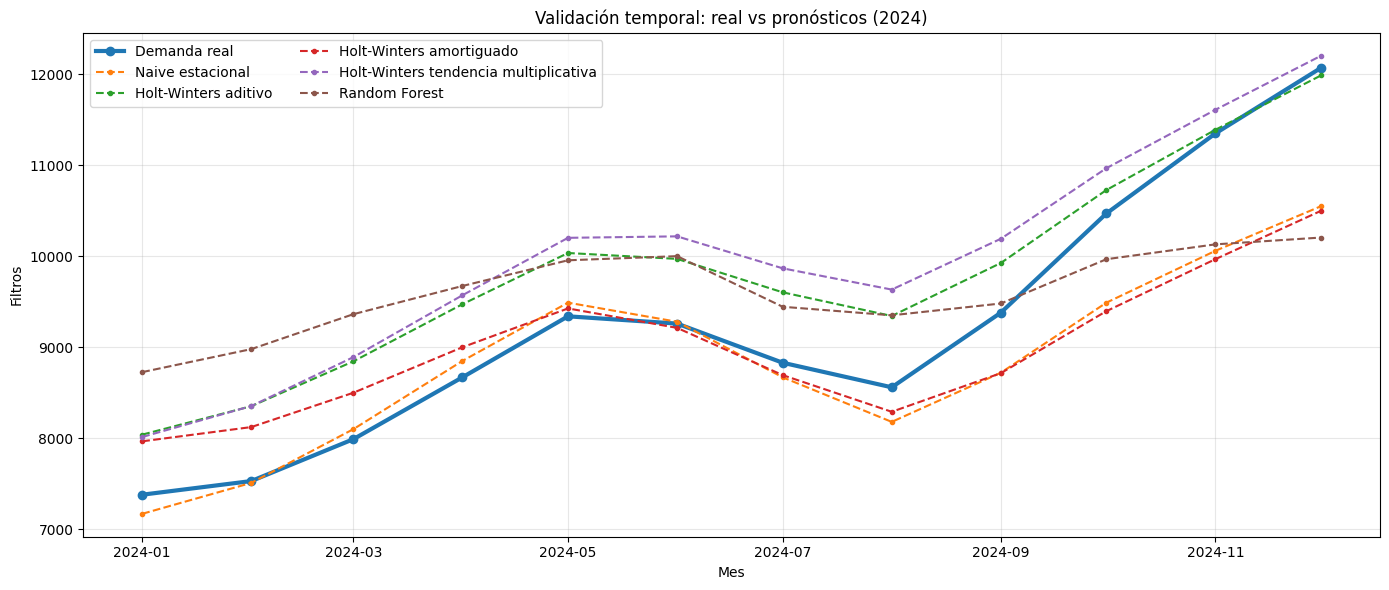

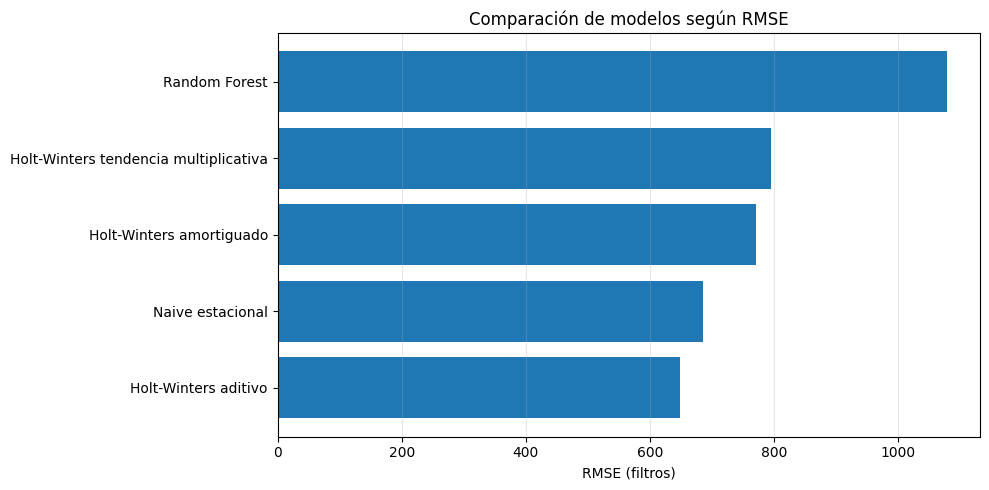

,Demanda real,Naive estacional,Holt-Winters aditivo,Holt-Winters amortiguado,Holt-Winters tendencia multiplicativa,Random Forest
Mes,,,,,,
2024-01-01,"7,380.00","7,170.00","8,039.98","7,966.57","8,014.00","8,726.86"
2024-02-01,"7,530.00","7,510.00","8,352.59","8,123.11","8,354.39","8,979.72"
2024-03-01,"7,990.00","8,100.00","8,845.13","8,500.14","8,891.32","9,363.28"
2024-04-01,"8,670.00","8,850.00","9,472.87","9,000.43","9,571.44","9,673.34"
2024-05-01,"9,340.00","9,490.00","10,035.58","9,426.56","10,202.37","9,955.50"
2024-06-01,"9,260.00","9,280.00","9,970.75","9,213.00","10,218.51","10,000.88"
2024-07-01,"8,830.00","8,670.00","9,603.64","8,694.01","9,867.25","9,444.86"
2024-08-01,"8,560.00","8,180.00","9,343.60","8,290.96","9,633.68","9,350.98"
2024-09-01,"9,380.00","8,720.00","9,925.83","8,715.50","10,191.94","9,480.86"


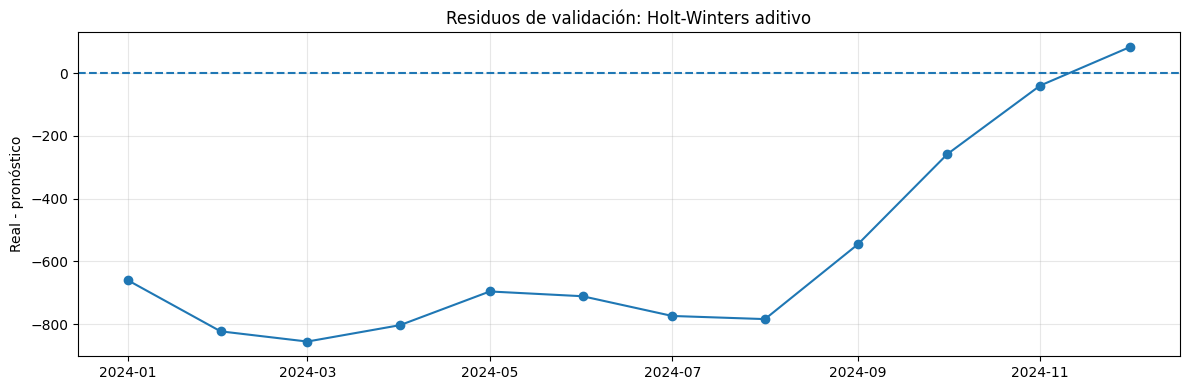

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(test.index, test.values, marker="o", linewidth=3, label="Demanda real")
for nombre, pred in preds.items():
    plt.plot(test.index, pred, marker=".", linestyle="--", label=nombre)
plt.title("Validación temporal: real vs pronósticos (2024)")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(ncol=2); plt.tight_layout(); plt.show()

orden = tabla_metricas.sort_values("RMSE")
plt.figure(figsize=(10,5))
plt.barh(orden["Modelo"], orden["RMSE"])
plt.title("Comparación de modelos según RMSE"); plt.xlabel("RMSE (filtros)")
plt.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

errores = pd.DataFrame({"Demanda real": test})
for nombre, pred in preds.items():
    errores[nombre] = pred
display(errores.round(2))

mejor_modelo = tabla_metricas.iloc[0]["Modelo"]
residuos = test.values - preds[mejor_modelo]
plt.figure(figsize=(12,4))
plt.axhline(0, linestyle="--")
plt.plot(test.index, residuos, marker="o")
plt.title(f"Residuos de validación: {mejor_modelo}")
plt.ylabel("Real - pronóstico"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
modelo_seleccionado = mejor_modelo
display(Markdown(f"### Modelo con menor RMSE: **{modelo_seleccionado}**"))
display(tabla_metricas[tabla_metricas["Modelo"] == modelo_seleccionado].round(2))

### Modelo con menor RMSE: **Holt-Winters aditivo**

,Modelo,MAE,MSE,RMSE,MAPE (%),Sesgo (real - pronóstico)
0,Holt-Winters aditivo,585.87,"421,870.92",649.52,6.85,-572.05


,Mes,Pronostico,Limite_inferior_aprox,Limite_superior_aprox
0,2025-01,"9,395.00","8,549.00","9,444.00"
1,2025-02,"9,674.00","8,828.00","9,723.00"
2,2025-03,"10,159.00","9,313.00","10,209.00"
3,2025-04,"10,797.00","9,951.00","10,846.00"
4,2025-05,"11,382.00","10,536.00","11,431.00"
5,2025-06,"11,313.00","10,467.00","11,362.00"
6,2025-07,"10,933.00","10,087.00","10,982.00"
7,2025-08,"10,671.00","9,825.00","10,720.00"
8,2025-09,"11,302.00","10,456.00","11,351.00"
9,2025-10,"12,161.00","11,315.00","12,210.00"


Total del horizonte: 134,146 filtros
Modelo utilizado: Holt-Winters aditivo
Residuos para banda empírica: 12


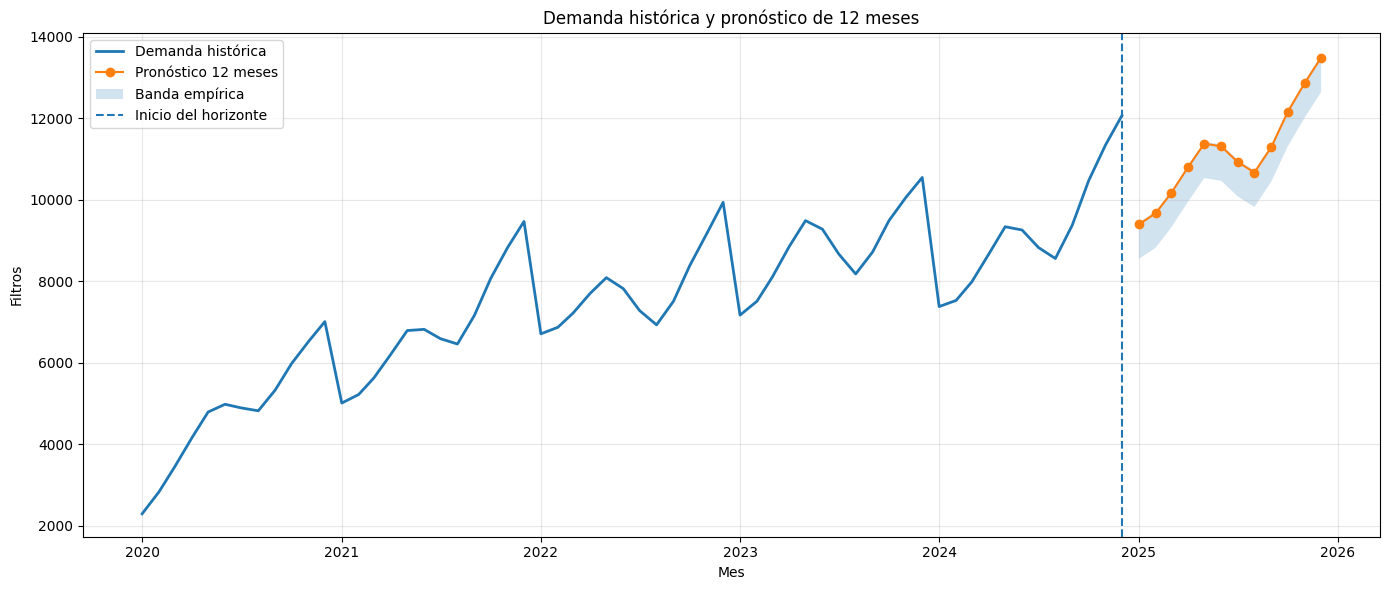

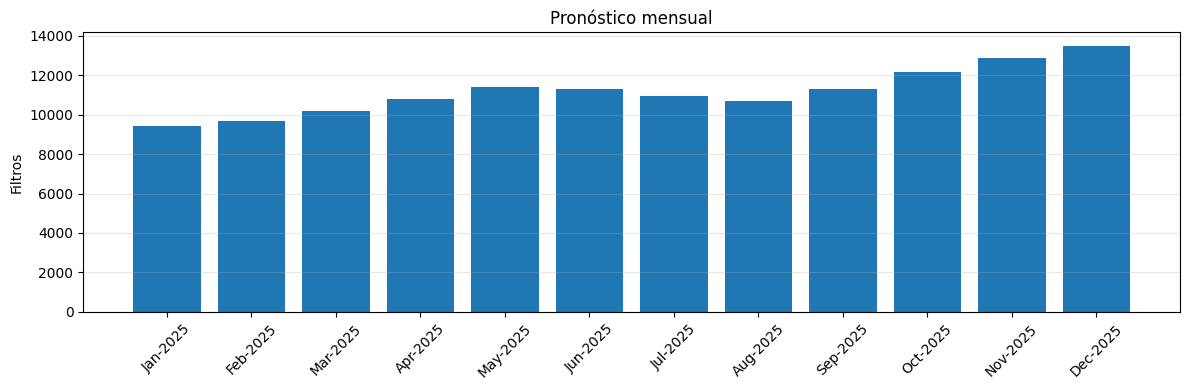

In [ ]:
def pronosticar(nombre, serie, h=12):
    if nombre == "Naive estacional":
        return np.tile(serie.iloc[-12:].values, int(np.ceil(h/12)))[:h]
    if nombre == "Holt-Winters aditivo":
        m = ExponentialSmoothing(serie, trend="add", seasonal="add", seasonal_periods=12,
            initialization_method="estimated").fit(optimized=True)
        return m.forecast(h).values
    if nombre == "Holt-Winters amortiguado":
        m = ExponentialSmoothing(serie, trend="add", damped_trend=True, seasonal="add",
            seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
        return m.forecast(h).values
    if nombre == "Holt-Winters tendencia multiplicativa":
        m = ExponentialSmoothing(serie, trend="mul", seasonal="add", seasonal_periods=12,
            initialization_method="estimated").fit(optimized=True)
        return m.forecast(h).values
    if nombre == "Random Forest":
        X, yy = dataset_rf(serie)
        m = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1).fit(X, yy)
        hist = serie.copy()
        fechas = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
        salida = []
        for fecha in fechas:
            valor = float(m.predict(features(hist, fecha))[0])
            salida.append(valor); hist.loc[fecha] = valor
        return np.asarray(salida)
    raise ValueError("Modelo no reconocido")

fechas_futuras = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
valores = pronosticar(modelo_seleccionado, y, 12)
q025, q975 = np.quantile(residuos, [0.025, 0.975])

pronostico = pd.DataFrame({
    "Mes": fechas_futuras.strftime("%Y-%m"),
    "Pronostico": valores,
    "Limite_inferior_aprox": np.maximum(0, valores + q025),
    "Limite_superior_aprox": np.maximum(0, valores + q975)
})
display(pronostico.round(0))
print(f"Total del horizonte: {pronostico['Pronostico'].sum():,.0f} filtros")
print(f"Modelo utilizado: {modelo_seleccionado}")
print(f"Residuos para banda empírica: {len(residuos)}")

fechas_plot = pd.to_datetime(pronostico["Mes"])
plt.figure(figsize=(14,6))
plt.plot(y.index, y.values, label="Demanda histórica", linewidth=2)
plt.plot(fechas_plot, valores, marker="o", label="Pronóstico 12 meses")
plt.fill_between(fechas_plot, pronostico["Limite_inferior_aprox"],
                 pronostico["Limite_superior_aprox"], alpha=.2, label="Banda empírica")
plt.axvline(y.index[-1], linestyle="--", label="Inicio del horizonte")
plt.title("Demanda histórica y pronóstico de 12 meses")
plt.xlabel("Mes"); plt.ylabel("Filtros"); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(12,4))
plt.bar(fechas_plot.dt.strftime("%b-%Y"), valores)
plt.title("Pronóstico mensual"); plt.ylabel("Filtros"); plt.xticks(rotation=45)
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

In [ ]:
fila_sel = tabla_metricas.loc[tabla_metricas["Modelo"] == modelo_seleccionado].iloc[0]
resumen = pd.DataFrame({
    "Indicador": ["Observaciones", "Inicio histórico", "Fin histórico", "Modelo seleccionado",
                  "MAE", "RMSE", "MAPE (%)", "Sesgo", "Total pronosticado"],
    "Resultado": [len(y), y.index.min().strftime("%Y-%m"), y.index.max().strftime("%Y-%m"),
                  modelo_seleccionado, fila_sel["MAE"], fila_sel["RMSE"], fila_sel["MAPE (%)"],
                  fila_sel["Sesgo (real - pronóstico)"], pronostico["Pronostico"].sum()]
})
display(resumen)

control.to_csv("control_calidad_sprint1.csv", index=False, encoding="utf-8-sig")
tabla_metricas.to_csv("metricas_validacion_sprint1.csv", index=False, encoding="utf-8-sig")
errores.to_csv("comparacion_validacion_2024.csv", encoding="utf-8-sig")
pronostico.to_csv("pronostico_12_meses_sprint1.csv", index=False, encoding="utf-8-sig")
resumen.to_csv("resumen_ejecutivo_sprint1.csv", index=False, encoding="utf-8-sig")

for nombre in ["control_calidad_sprint1.csv", "metricas_validacion_sprint1.csv",
               "comparacion_validacion_2024.csv", "pronostico_12_meses_sprint1.csv",
               "resumen_ejecutivo_sprint1.csv"]:
    files.download(nombre)

,Indicador,Resultado
0,Observaciones,60
1,Inicio histórico,2020-01
2,Fin histórico,2024-12
3,Modelo seleccionado,Holt-Winters aditivo
4,MAE,585.87
5,RMSE,649.52
6,MAPE (%),6.85
7,Sesgo,-572.05
8,Total pronosticado,"134,145.95"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>